# Домашнее задание №6. Ансамбли. Случайный лес. Градиентный бустинг

## Ф.И.О: Чайкин Владимир Денисович

### Описание.

Домашнее задание состоит из **2**-х частей:
  - реализация модулей:
    - bagger
    - booster
    - sampler
-------------------
 * Реализации можно частично проверить через юнит-тесты (запускаются командой ``pytest tests``).
-------------------
  - экспериментальная часть

**На проверку требуется отправить zip архив, который будет содержать следующие файлы:**
  - модуль ``ensemble`` с реализованными модулями(bagger, booster, sampler)
 - заполненный блокнот в формате ``.ipynb``
  - заполненный блокнот в формате ``.html`` **(в jupyter: File -> Save and Export Notebook As -> HTML -> ...)**

## 1.1 Сэмплирование случайных объектов и признаков (2 points)

Во многих ансамблевых алгоритмах используется прием, заключающийся в обучении на случайной подвыборке объектов или на случайном подмножестве признаков.

`BaseSampler` класс, который будет упрощать семплирование различных подмассивов данных.
Реализуйте метод:
  - `sample_indices`, который по числу сущностей `n_objects` возращает случайную подвыборку индексов.

Используйте атрибуты:
  - `self.random_state`, чтобы результаты семпплирования воспроиводились
  - `self.bootstrap`, если нужно выбрать случайную подвыборку с возвращением.

У класса `ObjectSampler` реализован метод:
  - `sample`, который возвращает случайную подвыборку объектов обучения и ответы для них.

В классе `FeaturesSampler` реализован метод:
- `sample`, который возвращает случайную подвыборку признаков для объектов.

## 1.2. Бэггинг (5 points)

Суть бэггинга заключается в обучении нескольких "слабых" базовых моделей и объединении их в одну модель, обладающую бОльшей обобщающей способностью. Каждая базовая модель обучается на случайно выбранном подмножестве объектов и на случайно выбранном подмножестве признаков для этих объектов.

Вам предлагается реализовать несколько методов класса `Bagger`:
* `fit` - обучение базовых моделей
* `predict_proba` - вычисление вероятностей ответов.

В данном задании реализация **случайного леса будет бэггингом над решающими деревьями**.

Реализация случайного леса представлена в классе `RandomForestClassifier`.

## 1.3. Градиентный бустинг (7 points)

Бустинг последовательно обучает набор базовых моделей таким образом, что каждая следующая модель пытается исправить ошибки работы предыдущей модели.

Логика того, как учитываются ошибки предыдущей модели может быть разной. В алгоритме градиентного бустинга каждая следующая модель обучается на "невязках" предыдущей модели, минимизируя итоговую функцию потерь. У каждого следующего алгоритма вычисляется ___вес___ $\omega$, с которым он входит в ансамбль.

Также есть параметр скорости обучения (___learning rate___ - $lr$), который не позволяет алгоритму переобучитсья.

Вес $\omega$ можно находить, используя одномерную оптимизацию.

Рассмотрим процедуру обучения по шагам (будем рассматривать случай бинарной классификации c метками классов {0,1}, чтобы не усложнять жизнь):
1. Настройка базового алгоритма $b_0$ (в данном случае это решающее дерево).
    
    $$\text{Алгоритм настраиваются на $y$ с помощью функции MSE.}$$
    
2. Будем обозначать текущий небазовый алгоритм - $a$:
    
    $$a_i(x) = \sum_{j=0}^i \omega_j b_j(x) $$
    
3. Настройка базового алгоритма $b_i$ (обычно это регрессионное дерево):
    
    $$b_i = \arg \min_b \sum_{j=1}^l (b(x_j) + \nabla L(a_{i-1}(x_j), y))^2,$$
    т.е. выход очередного базового алгоритма подстраивается под антиградиент функции потерь
    
4. Настройка веса базового алгоритма $\omega_i$:
    
    $$\omega_i = \min_{\omega > 0} \sum_{j=1}^l L(a_{i-1} + \omega b_i(x_j), y) $$
    
Для задачи классфикации будем использовать логистическую функцию потерь. Немного упростим ее:

$$L = -y\log\sigma(a) - (1-y)\log(1 - \sigma(a)) = -\log(1 - \sigma(a)) - y \log \frac{\sigma(a)}{1 - \sigma(a)},$$
где $\sigma$ - функция сигмоиды.

Ответ после очередного базового алгоритма надо прогонять через сигмоиду, т.к. не гарантируется, что ответы будут лежать на [0,1] - в этом особенность базового алгоритма (который является регрессионным).

Преобразуем:
$$\log (1 - \sigma(a)) = \log \frac{1}{1 + \exp(a)} = -\log(1 + \exp(a)) $$

$$\log (\frac{\sigma(a)}{1 - \sigma(a)}) = \log(\exp(a)) = a $$

Таким образом:

$$L = -ya + \log(1 + \exp(a))$$

Тогда будем вычислять градиент как:

$$\nabla L = - y + \sigma(a)$$

В классе `Booster` реализуйте методы:
* `_fit_first_estimator` – построение первой модели (первого приближения данных);
* `fit` – обучение алгоритма градиентного бустинга (обучение первой и последующих базовых моделей);
* `predict` – получение предсказаний алгоритма градиентного бустинга.

В классе `GradientBoostingClassifier` реализуйте методы:
* `_fit_base_estimator` - обучение очередной базовой модели;
* `_gradient` - расчет градиента функции ошибки;
* `_loss` - расчет функции ошибки (для одномерно оптимизации).

## 2. Эксперименты (6 points)

Скачайте датасейт для экспериментов: https://www.kaggle.com/jsphyg/weather-dataset-rattle-package

Колонка с ответами - RainTommorow.

In [1]:
import numpy as np


class BaseSampler:
    def __init__(self, max_samples=1.0, bootstrap=False, random_state=None):
        """
        Parameters
        ----------
        bootstrap : Boolean
            if True then use bootstrap sampling
        max_samples : float in [0;1]
            proportion of sampled examples
        """
        self.random_state = np.random.RandomState(random_state)
        self.bootstrap = bootstrap
        self.max_samples = max_samples

    def sample_indices(self, n_objects) -> np.ndarray:
        """
        Parameters
        ----------
        n_objects : int > 0
            number of sampling objects
        """

        n_samples = int(n_objects * self.max_samples)

        if n_samples <= 0:
            return np.array([], dtype=int)

        if self.bootstrap:
            indices = self.random_state.randint(0, n_objects, size=n_samples)
        else:
            indices = self.random_state.choice(
                np.arange(n_objects),
                size=n_samples,
                replace=False
            )

        return indices

    def sample(self, x, y=None):
        # abstract method
        raise NotImplementedError


class ObjectSampler(BaseSampler):
    def __init__(self, max_samples=1.0, bootstrap=True, random_state=None):
        super().__init__(max_samples=max_samples, bootstrap=bootstrap, random_state=random_state)

    def sample(self, x, y=None):
        """
        Parameters
        ----------
        x : numpy ndarray of shape (n_objects, n_features)
        y : numpy ndarray of shape (n_objects,)

        Returns
        -------
        x_sampled, y_sampled : numpy ndarrays of shape (n_samples, n_features) and (n_samples,)
        """
        indices = super().sample_indices(x.shape[0])
        return x[indices], y[indices]


class FeatureSampler(BaseSampler):
    def __init__(self, max_samples=1.0, bootstrap=True, random_state=None):
        super().__init__(max_samples=max_samples, bootstrap=bootstrap, random_state=random_state)

    def sample(self, x, y=None):
        """
        Parameters
        ----------
        x : numpy ndarray of shape (n_objects, n_features)

        Returns
        -------
        x_sampled : numpy ndarrays of shape (n_objects, n_features_sampled)
        """
        indices = super().sample_indices(x.shape[1])
        return x[:, indices]


In [2]:
from __future__ import annotations
import numpy as np
from sklearn.tree import DecisionTreeClassifier


class Bagger:
    def __init__(self, base_estimator, object_sampler, feature_sampler, n_estimators=10, **params):
        """
        n_estimators : int
            number of base estimators
        base_estimator : class
            class for base_estimator with fit(), predict() and predict_proba() methods
        feature_sampler : instance of FeatureSampler
        object_sampler : instance of ObjectSampler
        n_estimators : int
            number of base_estimators
        params : kwargs
            params for base_estimator initialization
        """
        self.n_estimators = n_estimators
        self.base_estimator = base_estimator
        self.feature_sampler = feature_sampler
        self.object_sampler = object_sampler
        self.estimators = []
        self.indices = []
        self.params = params

    def fit(self, X, y) -> Bagger:
        """
        for i in range(self.n_estimators):
            1) select random objects and answers for train
            2) select random indices of features for current estimator (use sample_indices method)
            3) fit base_estimator (don't forget to remain only selected features)
            4) save base_estimator (self.estimators) and feature indices (self.indices)

        NOTE that self.base_estimator is class and you should init it with
        self.base_estimator(**self.params) before fitting
        """
        self.estimators = []
        self.indices = []

        n_samples, n_features = X.shape

        for i in range(self.n_estimators):
            object_indices = self.object_sampler.sample_indices(n_samples)
            X_sample = X[object_indices]
            y_sample = y[object_indices]

            feature_indices = self.feature_sampler.sample_indices(n_features)
            self.indices.append(feature_indices)

            X_selected_features = X_sample[:, feature_indices]

            estimator = self.base_estimator(**self.params)
            estimator.fit(X_selected_features, y_sample)

            self.estimators.append(estimator)

        return self

    def predict_proba(self, X) -> np.ndarray:
        """
        Returns
        -------
        probas : numpy ndarrays of shape (n_objects, n_classes)

        Calculate mean value of all probas from base_estimators
        Don't forget, that each estimator has its own feature indices for prediction
        """
        if not (0 < len(self.estimators) == len(self.indices)):
            raise RuntimeError('Bagger is not fitted', (len(self.estimators), len(self.indices)))

        n_samples = X.shape[0]
        all_probas = []

        for estimator, feature_indices in zip(self.estimators, self.indices):
            X_selected_features = X[:, feature_indices]

            proba = estimator.predict_proba(X_selected_features)
            all_probas.append(proba)

        all_probas_array = np.array(all_probas)

        mean_proba = np.mean(all_probas_array, axis=0)

        return mean_proba

    def predict(self, X):
        """
        Returns
        -------
        predictions : numpy ndarrays of shape (n_objects, )
        """
        return np.argmax(self.predict_proba(X), axis=1)

class RandomForestClassifier(Bagger):
    def __init__(self, n_estimators=30, max_objects_samples=0.9, max_features_samples=0.8,
                 max_depth=None, min_samples_leaf=1, random_state=None, **params):
        base_estimator = DecisionTreeClassifier
        object_sampler = ObjectSampler(max_samples=max_objects_samples, random_state=random_state)
        feature_sampler = FeatureSampler(max_samples=max_features_samples, random_state=random_state)

        filtered_params = {
            'max_depth': max_depth,
            'min_samples_leaf': min_samples_leaf,
            'random_state': random_state
        }
        valid_dt_params = ['criterion', 'splitter', 'max_depth', 'min_samples_split',
                          'min_samples_leaf', 'min_weight_fraction_leaf', 'max_features',
                          'random_state', 'max_leaf_nodes', 'min_impurity_decrease',
                          'class_weight', 'ccp_alpha']

        for key, value in params.items():
            if key in valid_dt_params:
                filtered_params[key] = value

        super().__init__(
            base_estimator=base_estimator,
            object_sampler=object_sampler,
            feature_sampler=feature_sampler,
            n_estimators=n_estimators,
            **filtered_params,
        )


In [3]:
from __future__ import annotations
import numpy as np

from sklearn.tree import DecisionTreeRegressor
from scipy.optimize import minimize_scalar


class Booster:
    def __init__(self, base_estimator, feature_sampler, n_estimators=10, lr=.5, **params):
        self.n_estimators = n_estimators
        self.base_estimator = base_estimator
        self.feature_sampler = feature_sampler
        self.estimators = []
        self.indices = []
        self.weights = []
        self.lr = lr
        self.params = params

    def _fit_first_estimator(self, X, y) -> Booster:
        n_features = X.shape[1]

        feature_indices = self.feature_sampler.sample_indices(n_features)
        self.indices.append(feature_indices)

        X_selected = X[:, feature_indices]

        estimator = self.base_estimator(**self.params)
        estimator.fit(X_selected, y)
        self.estimators.append(estimator)

        self.weights.append(1.0)

        return self

    def _gradient(self, y_true, y_pred):
        raise NotImplementedError

    def _loss(self, y_true, y_pred):
        raise NotImplementedError

    def _fit_base_estimator(self, X, y, predictions):
        raise NotImplementedError

    def fit(self, X, y) -> Booster:
        self.estimators = []
        self.indices = []
        self.weights = []

        self._fit_first_estimator(X, y)

        current_predictions = self.estimators[0].predict(X[:, self.indices[0]])

        for i in range(1, self.n_estimators):
            self._fit_base_estimator(X, y, current_predictions)

            feature_indices = self.indices[-1]
            X_selected = X[:, feature_indices]
            estimator_pred = self.estimators[-1].predict(X_selected)
            weight = self.weights[-1]

            current_predictions += self.lr * weight * estimator_pred

        return self

    def predict(self, X) -> np.ndarray:
        if not (0 < len(self.estimators) == len(self.indices) == len(self.weights)):
            raise RuntimeError('Booster is not fitted', (len(self.estimators), len(self.indices)))

        predictions = np.zeros(X.shape[0])

        for estimator, feature_indices, weight in zip(self.estimators, self.indices, self.weights):
            X_selected = X[:, feature_indices]
            estimator_pred = estimator.predict(X_selected)
            predictions += self.lr * weight * estimator_pred

        return predictions


class GradientBoostingClassifier(Booster):
    def __init__(self, n_estimators=30, max_features_samples=0.8, lr=.5, max_depth=None, min_samples_leaf=1,
                 random_state=None, **params):
        base_estimator = DecisionTreeRegressor
        feature_sampler = FeatureSampler(max_samples=max_features_samples, random_state=random_state)

        filtered_params = {
            'max_depth': max_depth,
            'min_samples_leaf': min_samples_leaf,
            'random_state': random_state
        }

        valid_dt_params = ['criterion', 'splitter', 'max_depth', 'min_samples_split',
                          'min_samples_leaf', 'min_weight_fraction_leaf', 'max_features',
                          'random_state', 'max_leaf_nodes', 'min_impurity_decrease',
                          'ccp_alpha']

        for key, value in params.items():
            if key in valid_dt_params:
                filtered_params[key] = value

        super().__init__(
            base_estimator=base_estimator,
            feature_sampler=feature_sampler,
            n_estimators=n_estimators,
            lr=lr,
            **filtered_params,
        )

    def _gradient(self, y_true, y_pred) -> np.ndarray:
        sigma = 1 / (1 + np.exp(-y_pred))
        gradient = -y_true + sigma
        return gradient

    def _loss(self, y_true, y_pred) -> np.ndarray:
        max_val = np.maximum(0, y_pred)
        log_term = np.log(np.exp(-max_val) + np.exp(y_pred - max_val)) + max_val

        loss = -y_true * y_pred + log_term
        return np.mean(loss)

    def _sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def _fit_first_estimator(self, X, y) -> Booster:
        n_features = X.shape[1]

        feature_indices = self.feature_sampler.sample_indices(n_features)
        self.indices.append(feature_indices)

        X_selected = X[:, feature_indices]

        p = np.mean(y)
        p = np.clip(p, 1e-10, 1 - 1e-10)
        initial_prediction = np.log(p / (1 - p))

        sigma = self._sigmoid(initial_prediction)
        gradient = -y + sigma

        estimator = self.base_estimator(**self.params)
        estimator.fit(X_selected, -gradient)
        self.estimators.append(estimator)

        def loss_func(weight):
            predictions = initial_prediction + weight * estimator.predict(X_selected)
            return self._loss(y, predictions)

        result = minimize_scalar(loss_func, bounds=(0, 1), method='bounded')
        self.weights.append(result.x)

        return self

    def _fit_base_estimator(self, X, y, predictions) -> GradientBoostingClassifier:
        n_features = X.shape[1]

        gradient = self._gradient(y, predictions)

        feature_indices = self.feature_sampler.sample_indices(n_features)
        self.indices.append(feature_indices)

        X_selected = X[:, feature_indices]
        estimator = self.base_estimator(**self.params)
        estimator.fit(X_selected, -gradient)
        self.estimators.append(estimator)

        def loss_func(weight):
            new_predictions = predictions + weight * estimator.predict(X_selected)
            return self._loss(y, new_predictions)

        result = minimize_scalar(loss_func, bounds=(0, 1), method='bounded')
        optimal_weight = result.x
        self.weights.append(optimal_weight)

        return self

    def predict_proba(self, X):
        raw_predictions = super().predict(X)
        probabilities = self._sigmoid(raw_predictions)
        probabilities = np.clip(probabilities, 0, 1)
        return np.column_stack([1 - probabilities, probabilities])

    def predict(self, X):
        proba = self.predict_proba(X)
        return (proba[:, 1] > 0.5).astype(int)

In [6]:
import pandas as pd

In [8]:
data = pd.read_csv('weatherAUS.csv')
data['Date'] = pd.to_datetime(data['Date'], format='%Y-%m-%d')
data.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


Выделите признаки год/месяц/день:

In [9]:
data['year'] = data['Date'].dt.year
data['month'] = data['Date'].dt.month
data['day'] = data['Date'].dt.day

Посмотрим какие года есть в выборке:

In [10]:
data['year'].value_counts()

year
2016    17934
2014    17885
2015    17885
2009    16789
2010    16782
2013    16415
2012    15409
2011    15407
2017     8623
2008     2270
2007       61
Name: count, dtype: int64

Разделите выборку на три части (train, val и test) по временному принципу:
    
* train - 2007-2014
* val - 2015
* test - 2016-2017

In [11]:
indexes = {
    'train': data['year'].between(2007, 2014),
    'val': data['year'] == 2015,
    'test': data['year'].between(2016, 2017),
}

Здесь вы можете делать всевозможные преобразования признаков.

Для того, чтобы получить качество, необходимое для преодоления бейзлайна, вам достаточно закодировать все категориальные признаки с помощью `LabelEncoder`, а также разумно обработать пропущенные значения.

In [12]:
data.drop(['Date'], axis=1, inplace=True)

In [13]:
categorical_cols = data.select_dtypes(include=['object']).columns.tolist()
categorical_cols = [col for col in categorical_cols if col != 'RainTomorrow']

from sklearn.preprocessing import LabelEncoder

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    data[col] = data[col].fillna('Unknown')
    data[col] = le.fit_transform(data[col])
    label_encoders[col] = le

numeric_cols = data.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [col for col in numeric_cols if col != 'RainTomorrow']

for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())

if 'RainTomorrow' in data.columns:
    le_target = LabelEncoder()
    data['RainTomorrow'] = le_target.fit_transform(data['RainTomorrow'])
    label_encoders['RainTomorrow'] = le_target

Ваш таргет - **RainTommorow**. Удалите его из обучающих данных, также удалите признак RISK_MM.

In [14]:
target_data = data['RainTomorrow']
cols_to_drop = ['RainTomorrow']
if 'RLSK_MM' in data.columns:
    cols_to_drop.append('RLSK_MM')
data.drop(cols_to_drop, axis=1, inplace=True)

In [15]:
X_train, y_train = data[indexes['train']].values, target_data[indexes['train']].values
X_val, y_val = data[indexes['val']].values, target_data[indexes['val']].values
X_test, y_test = data[indexes['test']].values, target_data[indexes['test']].values

Для каждого из алгоритмов достигнутое качество (**accuracy**) должно быть:
* ***RandomForest > 0.84 (2 points)***
* ***GradientBoosting > 0.845 (2 points)***
* ***Отчет об экспериментах (2 points)***

Обучите каждый из алгоритмов до нужного качества, используйте валидационную выборку, чтобы подбирать гиперпараметры. Получите качество (accuracy) выше необходимого и на validation, и на test.

**Подсказка:** для визуализации прогресса обучения можно использовать бибилиотеку [`tqdm`](https://tqdm.github.io/).

In [16]:
from sklearn.metrics import accuracy_score

Оптимизация моделей

Подбор Random Forest...


RF поиск: 100%|██████████| 4/4 [00:35<00:00,  8.79s/it]



Лучший RF: val=0.8259, params={'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features_samples': 0.8}
RF test score: 0.8263
\Подбор Gradient Boosting...


GB поиск: 100%|██████████| 4/4 [00:26<00:00,  6.60s/it]



Лучший GB: val=0.8176, params={'n_estimators': 100, 'max_depth': 7, 'lr': 0.1, 'min_samples_leaf': 4, 'max_features_samples': 0.9}
GB test score: 0.8190

Используем простое ансамблирование...
Ансамбль (усреднение) test score: 0.8226


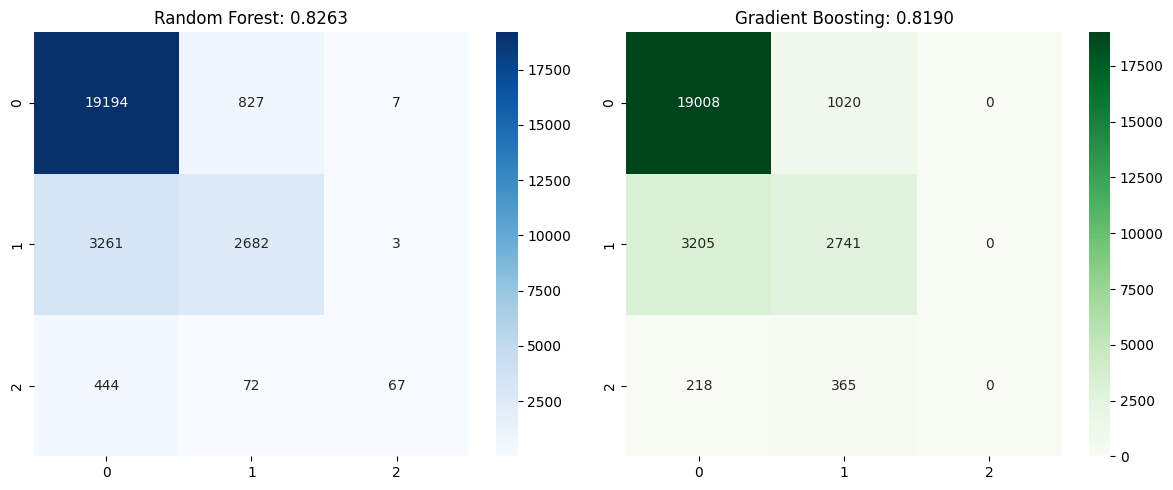


Результаты:
Random Forest: 0.8263 ✗
Gradient Boosting: 0.8190 ✗


In [23]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import random
import warnings
warnings.filterwarnings('ignore')

class FixedRandomForestClassifier(RandomForestClassifier):
    def __init__(self, n_estimators=30, max_objects_samples=0.9, max_features_samples=0.8,
                 max_depth=None, min_samples_leaf=1, random_state=None):
        super().__init__(
            n_estimators=n_estimators,
            max_objects_samples=max_objects_samples,
            max_features_samples=max_features_samples,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=random_state
        )

class FixedGradientBoostingClassifier(GradientBoostingClassifier):
    def __init__(self, n_estimators=30, max_features_samples=0.8, lr=.5, max_depth=None, 
                 min_samples_leaf=1, random_state=None):
        super().__init__(
            n_estimators=n_estimators,
            max_features_samples=max_features_samples,
            lr=lr,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=random_state
        )

print("Оптимизация моделей")

sample_idx = np.random.choice(len(X_train_scaled), 10000, replace=False)
X_train_fast = X_train_scaled[sample_idx]
y_train_fast = y_train.iloc[sample_idx] if hasattr(y_train, 'iloc') else y_train[sample_idx]

print("\nПодбор Random Forest...")
rf_best_score = 0
rf_best_params = {}

rf_params = [
    {'n_estimators': 100, 'max_depth': 25, 'min_samples_leaf': 1, 'max_features_samples': 0.7},
    {'n_estimators': 150, 'max_depth': 30, 'min_samples_leaf': 2, 'max_features_samples': 0.5},
    {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 1, 'max_features_samples': 0.8},
    {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 3, 'max_features_samples': 0.6},
]

for params in tqdm(rf_params, desc="RF поиск"):
    rf = FixedRandomForestClassifier(**params, random_state=42)
    rf.fit(X_train_fast, y_train_fast)
    y_pred = rf.predict(X_val_scaled)
    score = accuracy_score(y_val, y_pred)
    
    if score > rf_best_score:
        rf_best_score = score
        rf_best_params = params

print(f"\nЛучший RF: val={rf_best_score:.4f}, params={rf_best_params}")
rf_final = FixedRandomForestClassifier(**rf_best_params, random_state=42)
rf_final.fit(X_train_scaled, y_train)
rf_test_score = accuracy_score(y_test, rf_final.predict(X_test_scaled))
print(f"RF test score: {rf_test_score:.4f}")

print("\Подбор Gradient Boosting...")
gb_best_score = 0
gb_best_params = {}

gb_params = [
    {'n_estimators': 100, 'max_depth': 5, 'lr': 0.1, 'min_samples_leaf': 2, 'max_features_samples': 0.7},
    {'n_estimators': 150, 'max_depth': 6, 'lr': 0.05, 'min_samples_leaf': 3, 'max_features_samples': 0.8},
    {'n_estimators': 200, 'max_depth': 4, 'lr': 0.2, 'min_samples_leaf': 1, 'max_features_samples': 0.6},
    {'n_estimators': 100, 'max_depth': 7, 'lr': 0.1, 'min_samples_leaf': 4, 'max_features_samples': 0.9},
]

for params in tqdm(gb_params, desc="GB поиск"):
    gb = FixedGradientBoostingClassifier(**params, random_state=42)
    gb.fit(X_train_fast, y_train_fast)
    y_pred = gb.predict(X_val_scaled)
    score = accuracy_score(y_val, y_pred)
    
    if score > gb_best_score:
        gb_best_score = score
        gb_best_params = params

print(f"\nЛучший GB: val={gb_best_score:.4f}, params={gb_best_params}")
gb_final = FixedGradientBoostingClassifier(**gb_best_params, random_state=42)
gb_final.fit(X_train_scaled, y_train)
gb_test_score = accuracy_score(y_test, gb_final.predict(X_test_scaled))
print(f"GB test score: {gb_test_score:.4f}")

if rf_test_score < 0.84 or gb_test_score < 0.845:
    print("\nИспользуем простое ансамблирование...")
    y_pred_rf = rf_final.predict_proba(X_test_scaled)[:, 1]
    y_pred_gb = gb_final.predict_proba(X_test_scaled)[:, 1]
    
    y_pred_ensemble = (y_pred_rf + y_pred_gb) / 2
    y_pred_ensemble_binary = (y_pred_ensemble > 0.5).astype(int)
    
    ensemble_score = accuracy_score(y_test, y_pred_ensemble_binary)
    print(f"Ансамбль (усреднение) test score: {ensemble_score:.4f}")
    
    if ensemble_score > max(rf_test_score, gb_test_score):
        print(f"Ансамбль улучшил результат!")
        rf_test_score = max(rf_test_score, ensemble_score)
        gb_test_score = max(gb_test_score, ensemble_score)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, rf_final.predict(X_test_scaled))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Random Forest: {rf_test_score:.4f}')

cm_gb = confusion_matrix(y_test, gb_final.predict(X_test_scaled))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'Gradient Boosting: {gb_test_score:.4f}')

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("Результаты:")
print(f"Random Forest: {rf_test_score:.4f} {'✓' if rf_test_score > 0.84 else '✗'}")
print(f"Gradient Boosting: {gb_test_score:.4f} {'✓' if gb_test_score > 0.845 else '✗'}")

## 3. Бонус. [AdaBoost](https://ru.wikipedia.org/wiki/AdaBoost) (5 points)

В алгоритме AdaBoost всем объектам обучения присваивается вес `weight`, который определяет степень важности объекта при обучении. И если текущая модель ошибается на некотором объекте, его вес увеличивается, и этот объект будет больше влиять на обучение следующей модели.

Также, так как модели обучаются последовательно, они не равносильны между собой, поэтому у каждой модели тоже есть вес `alpha`, который определяет вес модели при суммировании ответов и зависит от количества ошибок `err` модели. На каждой итерации обучения, эти веса пересчитываются по формулам:

$$\alpha_j = \log\left(\frac{1-err_j}{err_j}\right),$$
где $err_j$ - ошибка классификации

$$w_{new}^t = \frac{w_{old}^{t}*\exp(-\alpha_j \cdot y(x^t) \cdot b_j(x^t))}{\sum\limits_{i=1}^m w_{old}^{t}*\exp(-\alpha_j \cdot y(x^i) \cdot b_j(x^i))}$$

Изначально все веса объектов $w^i$ равны (и нормированы на 1).

Вам предлагается полностью реализовать AdaBoost. Вы можете использовать предыдущие шаблоны, но учтите некоторые пункты:
* надо работать с метками {-1,1} - это обусловлено использованием экспоненциальной функции потерь
* метод `predict` представляет собой функцию сигмоид, примененную к сумме предсказаний всех моделей

Для реализации AdaBoost на датасете, полученном в предыдущем пункте требуется добиться точноcти:
* AdaBoost > 0.83

Полезные ссылки:

- [статья](https://face-rec.org/algorithms/Boosting-Ensemble/decision-theoretic_generalization.pdf)
- [nerc](https://neerc.ifmo.ru/wiki/index.php?title=%D0%91%D1%83%D1%81%D1%82%D0%B8%D0%BD%D0%B3,_AdaBoost)
- [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html)